# Reranker-Only Evaluation on the Logged MIND Slates

This notebook evaluates the **reranking stage on its own**. Every impression keeps the exact
slate that MIND logged, and each model only reorders those articles. No candidate generation
is involved, and every candidate has a known click label.

Three models are compared on the same validation and test slates:

| Role | Model | Learned? |
|---|---|---|
| Rule baseline | Causal popularity: smoothed prior article CTR | No |
| Rule baseline | Content similarity: entity cosine to the user's causal click profile | No |
| Selected model | RR_4 branch reranker, `+metadata` architecture, `softmax+lambda_ndcg` loss, trained on the full training set | Yes |

The selected model is loaded from its saved checkpoint; nothing is trained here. Its scores are
recomputed and checked against the metrics recorded by `RR_4_branch_interaction.ipynb`, which
confirms the checkpoint, preprocessor and data copies are the same ones that were selected.

**How this differs from the end-to-end pipeline** (`2_CG_RR_E2E`): there the reranker orders
*generated* candidates, most of which were never shown, so their relevance is unknown. Here
every candidate was shown, so the metrics are complete-label ranking metrics. They are an upper
bound on how well the reranker orders articles, not an estimate of the full system.

# 1. Setup

## 1.1 Load Packages

In [1]:
import json
import sys
import time
from datetime import datetime, timezone
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl
import pyarrow.parquet as pq
import torch
from IPython.display import display
from torch import nn

## 1.2 Set Up Paths

Set `ENVIRONMENT` to `"colab"` to read everything from Google Drive. The folder layout under
`DATA_ROOT` is the same in both modes, so only the two roots change.

| Path | Holds |
|---|---|
| `PROJECT_ROOT` | The repository; only `5_Models/5_02_Reranking/rr_evaluation.py` is imported |
| `RUN` | Ranking features, click labels and causal click histories from feature engineering |
| `REPRESENTATIONS` | Frozen article vectors and the article index |
| `MODEL_DIR` | The selected RR_4 run: `preprocessor.joblib` and `<FINAL_MODEL_NAME>/model.pt` |
| `OUTPUT_DIR` | Score files written by this notebook |
| `RESULTS` | Metric tables written by this notebook (`pe_rr_only_*`) |

In [2]:
ENVIRONMENT = "local"  # "local" or "colab"

if ENVIRONMENT == "colab":
    from google.colab import drive

    drive.mount("/content/drive")
    PROJECT_ROOT = Path("/content/drive/MyDrive/BT4222-Group-6-")
    DATA_ROOT = Path("/content/drive/MyDrive/v3-mindsmall")
else:
    PROJECT_ROOT = Path("/Users/numkoos/Downloads/BT4222-Group-6-")
    DATA_ROOT = Path("/Users/numkoos/Downloads/v3-mindsmall")

RUN = DATA_ROOT / "4_Feature_Engineering" / "artifacts" / "prequential-all"
REPRESENTATIONS = DATA_ROOT / "3_Representations" / "artifacts"
MODEL_DIR = DATA_ROOT / "5_Models" / "5_02_Reranking" / "artifacts" / "branch_interaction"
OUTPUT_DIR = DATA_ROOT / "5_Models" / "5_03_Pipeline_Evaluation" / "artifacts" / "1_RR_only"
RESULTS = DATA_ROOT / "results"

sys.path.insert(0, str(PROJECT_ROOT / "5_Models" / "5_02_Reranking"))
from rr_evaluation import RerankingEvaluator, compare_results, score_and_evaluate

print("Environment:", ENVIRONMENT)
print("Project root:", PROJECT_ROOT)
print("Data root:", DATA_ROOT)

Environment: local
Project root: /Users/numkoos/Downloads/BT4222-Group-6-
Data root: /Users/numkoos/Downloads/v3-mindsmall


## 1.3 Configuration

- `SPLITS`: validation is reported for context; test is the headline. Nothing here is tuned,
  so test is never used to make a choice.
- `CONTENT_RULE`: the content-similarity rule selected on validation in
  `RR_content_similarity_baseline.ipynb` (entity cosine).
- `REUSE_SCORES`: `False` rescores every model, which is what makes the reproduction check
  meaningful. Set it to `True` to evaluate score files already in `OUTPUT_DIR` (faster on Colab).
- The RR_4 model settings below must match the saved checkpoint; loading fails loudly if not.

In [3]:
SPLITS = ("validation", "test")
K_VALUES = (5, 10)
SEED = 4222
REUSE_SCORES = False

POPULARITY_MODEL = "popularity_smoothed_prior_article_ctr"
CONTENT_RULE = "entity"  # "text", "entity" or "fusion"
CONTENT_TEXT_WEIGHT = 0.50  # only used by the fusion rule
CONTENT_MODEL = f"content_{CONTENT_RULE}_cosine" if CONTENT_RULE != "fusion" else (
    f"content_fusion_text_{CONTENT_TEXT_WEIGHT:.2f}"
)
FINAL_MODEL_NAME = "branch_plus_metadata__softmax_plus_lambda_ndcg__full_data"
MODEL_NAMES = [POPULARITY_MODEL, CONTENT_MODEL, FINAL_MODEL_NAME]
MODEL_LABELS = {
    POPULARITY_MODEL: "Popularity (rule)",
    CONTENT_MODEL: "Content similarity (rule)",
    FINAL_MODEL_NAME: "RR_4 +metadata (selected)",
}

# RR_4 settings (must match RR_4_branch_interaction.ipynb)
MODEL_DIM = 64
ATTENTION_HEADS = 2
ATTENTION_DROPOUT = 0.10
HIDDEN_DIMS = (256, 64)
DROPOUT = 0.20
HISTORY_CAP = 30
SHORT_TERM_CAP = 10
SCORING_BATCH_ROWS = 4096

DEVICE = (
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)
torch.manual_seed(SEED)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
RESULTS.mkdir(parents=True, exist_ok=True)
print("Device:", DEVICE)
print("Models:", MODEL_NAMES)

Device: mps
Models: ['popularity_smoothed_prior_article_ctr', 'content_entity_cosine', 'branch_plus_metadata__softmax_plus_lambda_ndcg__full_data']


## 1.4 Check the Inputs

Every file the notebook reads is listed here and checked before anything heavy runs, so a
missing Drive upload fails immediately with its path.

In [4]:
def folder_size(path):
    if path.is_file():
        return path.stat().st_size
    return sum(item.stat().st_size for item in path.rglob("*") if item.is_file())


REQUIRED_INPUTS = {
    "rr_evaluation.py": PROJECT_ROOT / "5_Models" / "5_02_Reranking" / "rr_evaluation.py",
    "feature schema": RUN / "feature_schema.json",
    **{f"ranking features ({s})": RUN / f"ranking_features_{s}" for s in SPLITS},
    **{f"labels ({s})": RUN / f"labels_{s}" for s in SPLITS},
    **{f"request profiles ({s})": RUN / f"request_profiles_{s}" for s in SPLITS},
    "article index": REPRESENTATIONS / "article_index.parquet",
    "text vectors": REPRESENTATIONS / "text64.npy",
    "entity vectors": REPRESENTATIONS / "article_entity100.npy",
    "RR_4 preprocessor": MODEL_DIR / "preprocessor.joblib",
    "RR_4 checkpoint": MODEL_DIR / FINAL_MODEL_NAME / "model.pt",
}

manifest = pd.DataFrame(
    [
        {
            "input": name,
            "exists": path.exists(),
            "size_mb": round(folder_size(path) / 1e6, 1) if path.exists() else None,
            "path": str(path),
        }
        for name, path in REQUIRED_INPUTS.items()
    ]
)
display(manifest)
missing_inputs = manifest.loc[~manifest["exists"], "path"].tolist()
if missing_inputs:
    raise FileNotFoundError("Missing inputs:\n" + "\n".join(missing_inputs))

,input,exists,size_mb,path
0,rr_evaluation.py,True,0.0,/Users/numkoos/Downloads/BT4222-Group-6-/5_Mod...
1,feature schema,True,0.0,/Users/numkoos/Downloads/v3-mindsmall/4_Featur...
2,ranking features (validation),True,63.8,/Users/numkoos/Downloads/v3-mindsmall/4_Featur...
3,ranking features (test),True,62.9,/Users/numkoos/Downloads/v3-mindsmall/4_Featur...
4,labels (validation),True,1.8,/Users/numkoos/Downloads/v3-mindsmall/4_Featur...
5,labels (test),True,1.8,/Users/numkoos/Downloads/v3-mindsmall/4_Featur...
6,request profiles (validation),True,4.8,/Users/numkoos/Downloads/v3-mindsmall/4_Featur...
7,request profiles (test),True,4.7,/Users/numkoos/Downloads/v3-mindsmall/4_Featur...
8,article index,True,17.3,/Users/numkoos/Downloads/v3-mindsmall/3_Repres...
9,text vectors,True,13.1,/Users/numkoos/Downloads/v3-mindsmall/3_Repres...


# 2. Load and Inspect the Data

## 2.1 Feature Schema

The frozen feature schema lists the causal tabular columns. The selected model reads all of
them; the two rule baselines read only the columns they need.

In [5]:
schema = json.loads((RUN / "feature_schema.json").read_text())
FEATURES = schema["model_columns"]
CATEGORICAL = [name for name in schema.get("categorical_columns", []) if name in FEATURES]

POPULARITY_COLUMNS = ["smoothed_prior_article_ctr"]
CONTENT_COLUMNS = [
    "smoothed_prior_article_ctr",
    "text_cosine", "entity_cosine",
    "text_match_valid", "entity_match_valid",
    "no_text_profile", "no_entity_profile",
]
missing_columns = sorted(set(CONTENT_COLUMNS) - set(FEATURES))
if missing_columns:
    raise ValueError(f"Baseline columns missing from the feature schema: {missing_columns}")

print(f"{len(FEATURES)} model features: {len(FEATURES) - len(CATEGORICAL)} numeric, "
      f"{len(CATEGORICAL)} categorical")
print("Categorical:", CATEGORICAL)

50 model features: 48 numeric, 2 categorical
Categorical: ['category_code', 'subcategory_code']


## 2.2 Logged Slates

One row per (impression, shown article). The ranking features and labels must hold exactly
the same pairs, otherwise the evaluator would reject the score files later.

In [6]:
def scan_split(split):
    features = pl.scan_parquet(RUN / f"ranking_features_{split}" / "*.parquet")
    labels = pl.scan_parquet(RUN / f"labels_{split}" / "*.parquet")
    return features, labels


slate_summary, slate_sizes = [], {}
for split in SPLITS:
    features, labels = scan_split(split)
    keys = features.select("impression_uid", "news_code", "user_code", "timestamp").collect()
    label_frame = labels.select("impression_uid", "news_code", "clicked").collect()
    joined = keys.join(label_frame, on=["impression_uid", "news_code"], how="inner")
    if not (joined.height == keys.height == label_frame.height):
        raise ValueError(f"{split}: ranking features and labels disagree on the logged pairs")

    per_impression = joined.group_by("impression_uid").agg(
        pl.len().alias("slate_size"), pl.col("clicked").sum().alias("clicks")
    )
    slate_sizes[split] = per_impression
    slate_summary.append({
        "split": split,
        "rows": joined.height,
        "impressions": per_impression.height,
        "users": joined["user_code"].n_unique(),
        "articles": joined["news_code"].n_unique(),
        "clicks": int(joined["clicked"].sum()),
        "row_ctr": joined["clicked"].mean(),
        "impressions_without_click": int((per_impression["clicks"] == 0).sum()),
        "first_timestamp": joined["timestamp"].min(),
        "last_timestamp": joined["timestamp"].max(),
    })

display(pl.DataFrame(slate_summary))

split,rows,impressions,users,articles,clicks,row_ctr,impressions_without_click,first_timestamp,last_timestamp
str,i64,i64,i64,i64,i64,f64,i64,datetime[μs],datetime[μs]
"""validation""",1231673,31624,20884,6084,47961,0.03894,0,2019-11-13 00:01:00,2019-11-13 23:59:21
"""test""",1222429,30270,20179,6144,46825,0.038305,0,2019-11-14 00:00:00,2019-11-14 23:59:13


In [7]:
features_preview, _ = scan_split("validation")
display(features_preview.select("impression_uid", "user_code", "news_code", "timestamp",
                                *CONTENT_COLUMNS).head(5).collect())

impression_uid,user_code,news_code,timestamp,smoothed_prior_article_ctr,text_cosine,entity_cosine,text_match_valid,entity_match_valid,no_text_profile,no_entity_profile
i64,i64,i64,datetime[ns],f32,f32,f32,f32,f32,f32,f32
10154218,11484,12029,2019-11-13 00:01:00,0.141185,0.323173,0.452622,1.0,1.0,0.0,0.0
10154218,11484,47020,2019-11-13 00:01:00,0.112813,0.786995,0.0,1.0,0.0,0.0,0.0
10135780,6069,103,2019-11-13 00:01:23,0.024634,0.387611,-0.035632,1.0,1.0,0.0,0.0
10135780,6069,261,2019-11-13 00:01:23,0.019184,0.435232,0.0,1.0,0.0,0.0,0.0
10135780,6069,1644,2019-11-13 00:01:23,0.044654,0.406151,0.622514,1.0,1.0,0.0,0.0


**Slate shape.** The number of articles shown per impression and the number clicked. A random
ordering of a slate with `n` articles and one click has an expected reciprocal rank of
`H(n)/n`, so large slates make the task harder.

split,size_q0,size_q25,size_q50,size_q75,size_q90,size_q99,size_q100,mean_clicks,max_clicks
str,f64,f64,f64,f64,f64,f64,f64,f64,i64
"""validation""",2.0,11.0,26.0,53.0,94.0,180.0,299.0,1.516601,27
"""test""",2.0,12.0,27.0,55.0,97.0,182.0,295.0,1.546911,35


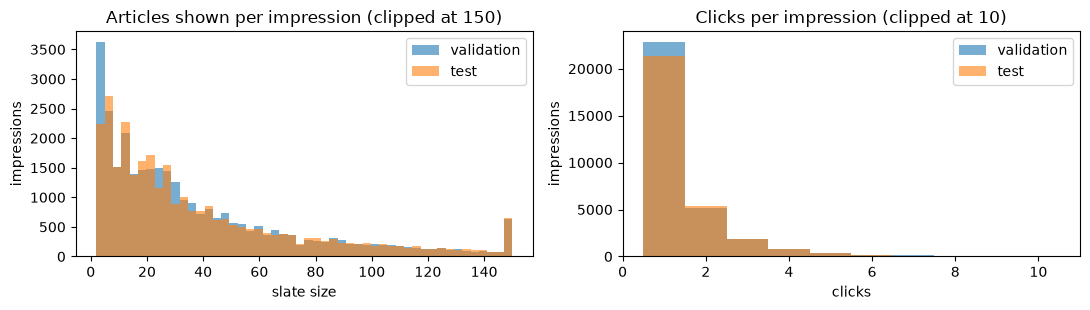

In [8]:
quantiles = [0.0, 0.25, 0.5, 0.75, 0.9, 0.99, 1.0]
display(pl.concat([
    frame.select(
        pl.lit(split).alias("split"),
        *[pl.col("slate_size").quantile(q).alias(f"size_q{int(q * 100)}") for q in quantiles],
        pl.col("clicks").mean().alias("mean_clicks"),
        pl.col("clicks").max().alias("max_clicks"),
    )
    for split, frame in slate_sizes.items()
]))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
for split, frame in slate_sizes.items():
    axes[0].hist(frame["slate_size"].clip(upper_bound=150), bins=50, alpha=0.6, label=split)
    axes[1].hist(frame["clicks"].clip(upper_bound=10), bins=np.arange(0.5, 11.5), alpha=0.6, label=split)
axes[0].set(title="Articles shown per impression (clipped at 150)", xlabel="slate size", ylabel="impressions")
axes[1].set(title="Clicks per impression (clipped at 10)", xlabel="clicks", ylabel="impressions")
for axis in axes:
    axis.legend()
plt.tight_layout()
plt.show()

## 2.3 Causal Click Histories

`request_profiles_<split>` stores, for every impression, the article rows the user clicked
**strictly before** that impression. The selected model reads the newest `HISTORY_CAP` of them;
the content baseline's profile cosines were built from the same histories.

History length also defines the cohorts used in section 5.2.

In [9]:
def load_profiles(split):
    profiles = (
        pl.scan_parquet(RUN / f"request_profiles_{split}" / "*.parquet")
        .select("impression_uid", "full_history_rows")
        .collect()
    )
    return profiles


HISTORY_BINS = [(0, 0, "0 clicks"), (1, 5, "1-5 clicks"), (6, 20, "6-20 clicks"), (21, None, "21+ clicks")]


def history_cohorts(profiles):
    length = pl.col("full_history_rows").list.len()
    cohort = pl.lit(None, dtype=pl.Utf8)
    for low, high, label in reversed(HISTORY_BINS):
        condition = length >= low if high is None else length.is_between(low, high)
        cohort = pl.when(condition).then(pl.lit(label)).otherwise(cohort)
    return profiles.select("impression_uid", length.alias("history_length"), cohort.alias("cohort"))


profiles_by_split = {split: load_profiles(split) for split in SPLITS}
cohorts_by_split = {split: history_cohorts(profiles) for split, profiles in profiles_by_split.items()}

for split in SPLITS:
    impressions = slate_sizes[split].select("impression_uid")
    cohorts = cohorts_by_split[split]
    if impressions.join(cohorts, on="impression_uid", how="anti").height:
        raise ValueError(f"{split}: some impressions have no request profile")
    cohorts_by_split[split] = cohorts.join(impressions, on="impression_uid", how="semi")

display(pl.concat([
    cohorts.group_by("cohort").agg(pl.len().alias("impressions"))
    .with_columns(pl.lit(split).alias("split"), (pl.col("impressions") / pl.col("impressions").sum()).alias("share"))
    for split, cohorts in cohorts_by_split.items()
]).pivot(on="split", index="cohort", values="share")
  .sort(pl.col("cohort").replace_strict({label: i for i, (_, _, label) in enumerate(HISTORY_BINS)})))

cohort,validation,test
str,f64,f64
"""0 clicks""",0.003605,0.003105
"""1-5 clicks""",0.115482,0.103337
"""6-20 clicks""",0.343252,0.340436
"""21+ clicks""",0.537661,0.553122


## 2.4 Article Representations

All article inputs are indexed by `article_row`; row 0 is padding. Every logged candidate must
map to an article row, otherwise the selected model cannot encode it.

In [10]:
article_index = pl.read_parquet(
    REPRESENTATIONS / "article_index.parquet",
    columns=["news_code", "article_row", "category_code", "subcategory_code"],
)
NEWS_TO_ROW = dict(zip(article_index["news_code"].to_list(), article_index["article_row"].to_list()))

TEXT_VECTORS = np.array(np.load(REPRESENTATIONS / "text64.npy", mmap_mode="r"), dtype=np.float32)
ENTITY_VECTORS = np.array(np.load(REPRESENTATIONS / "article_entity100.npy", mmap_mode="r"), dtype=np.float32)
N_ARTICLES = TEXT_VECTORS.shape[0]
ARTICLE_CATEGORY = np.zeros(N_ARTICLES, dtype=np.int64)
ARTICLE_SUBCATEGORY = np.zeros(N_ARTICLES, dtype=np.int64)
ARTICLE_CATEGORY[article_index["article_row"].to_numpy()] = article_index["category_code"].to_numpy()
ARTICLE_SUBCATEGORY[article_index["article_row"].to_numpy()] = article_index["subcategory_code"].to_numpy()

print(f"Article rows: {N_ARTICLES:,} (text {TEXT_VECTORS.shape}, entity {ENTITY_VECTORS.shape})")
print(f"Categories: {ARTICLE_CATEGORY.max()}, subcategories: {ARTICLE_SUBCATEGORY.max()}")
for split in SPLITS:
    features, _ = scan_split(split)
    codes = features.select(pl.col("news_code").unique()).collect()["news_code"]
    unmapped = codes.filter(~codes.is_in(list(NEWS_TO_ROW)))
    if unmapped.len():
        raise ValueError(f"{split}: {unmapped.len()} logged articles have no article row")
    print(f"{split}: all {codes.len():,} logged articles map to an article row")

Article rows: 51,283 (text (51283, 64), entity (51283, 100))
Categories: 17, subcategories: 257
validation: all 6,084 logged articles map to an article row
test: all 6,144 logged articles map to an article row


# 3. Rule-Based Baselines

Both rules read causal features that feature engineering already computed, so they have no
trainable parameters. They are copied unchanged from `5_02_Reranking/1_Baseline`.

**Popularity.** For candidate $a$ at impression time $t$:

$$s(a,t) = \frac{c_{a,<t} + \alpha\, p_{<t}}{e_{a,<t} + \alpha}$$

where $c$ and $e$ are the article's earlier clicks and exposures and $p$ is the expanding
global CTR. The same score is given to every user.

**Content similarity.** The cosine between the candidate and the user's causal clicked-history
profile (mean of earlier clicked article vectors), using text, entity or a blend:

- A candidate with no valid vector scores $-2$, below every valid cosine in $[-1, 1]$.
- A user with no profile falls back to the popularity score.

In [11]:
MISSING_SCORE = -2.0


def popularity_score(frame):
    return frame["smoothed_prior_article_ctr"].to_numpy(dtype=float)


def content_score(frame, rule=CONTENT_RULE, text_weight=CONTENT_TEXT_WEIGHT):
    prior = frame["smoothed_prior_article_ctr"].to_numpy(dtype=float)
    text = frame["text_cosine"].to_numpy(dtype=float)
    entity = frame["entity_cosine"].to_numpy(dtype=float)
    text_valid = frame["text_match_valid"].to_numpy(dtype=bool)
    entity_valid = frame["entity_match_valid"].to_numpy(dtype=bool)
    no_text_profile = frame["no_text_profile"].to_numpy(dtype=bool)
    no_entity_profile = frame["no_entity_profile"].to_numpy(dtype=bool)

    if rule == "text":
        return np.where(no_text_profile, prior, np.where(text_valid, text, MISSING_SCORE))
    if rule == "entity":
        return np.where(no_entity_profile, prior, np.where(entity_valid, entity, MISSING_SCORE))
    blended = np.where(
        text_valid & entity_valid,
        text_weight * text + (1 - text_weight) * entity,
        np.where(text_valid, text, np.where(entity_valid, entity, MISSING_SCORE)),
    )
    return np.where(no_text_profile & no_entity_profile, prior, blended)

# 4. Selected Model: RR_4 Branch Reranker

`RR_4_branch_interaction.ipynb` selected the `+metadata` architecture with the combined
`softmax+lambda_ndcg` loss, then retrained it on every training impression with early stopping.
The classes below are copied from that notebook, with the article arrays passed in explicitly.
Loading uses `strict=True`, so any difference in architecture fails instead of silently
leaving weights untrained.

```text
[tabular features ; candidate news vector ; user vector]
    → Dense 256 → ReLU → Dropout → Dense 64 → ReLU → Dropout → logit

news vector = Linear+LayerNorm( text64 ; category emb ; subcategory emb ; Linear(entity100) )
user vector = self-attention over the newest 30 clicked news vectors → additive attention pool
```

## 4.1 Model Classes

In [12]:
class AdditiveAttention(nn.Module):
    """Pool a sequence into one vector with learned relevance weights."""

    def __init__(self, dim):
        super().__init__()
        self.proj = nn.Linear(dim, dim)
        self.query = nn.Parameter(torch.randn(dim) * 0.02)

    def forward(self, states, padding_mask):
        all_padded = padding_mask.all(dim=1)
        safe_mask = padding_mask.clone()
        safe_mask[all_padded, 0] = False
        scores = torch.tanh(self.proj(states)) @ self.query
        weights = torch.softmax(scores.masked_fill(safe_mask, -1e9), dim=1)
        weights = weights.masked_fill(padding_mask, 0.0)
        weights = weights / weights.sum(dim=1, keepdim=True).clamp(min=1e-8)
        return (weights.unsqueeze(-1) * states).sum(dim=1)

In [13]:
class NewsEncoder(nn.Module):
    """Map article rows to MODEL_DIM news vectors from the enabled article inputs."""

    def __init__(self, config):
        super().__init__()
        if config["title_encoder"]:
            raise NotImplementedError("The selected model does not use the title encoder")
        self.config = config
        self.register_buffer("text", torch.from_numpy(TEXT_VECTORS), persistent=False)
        width = self.text.shape[1]
        if config["metadata"]:
            self.register_buffer("entity", torch.from_numpy(ENTITY_VECTORS), persistent=False)
            self.register_buffer("category", torch.from_numpy(ARTICLE_CATEGORY), persistent=False)
            self.register_buffer("subcategory", torch.from_numpy(ARTICLE_SUBCATEGORY), persistent=False)
            self.category_embedding = nn.Embedding(int(ARTICLE_CATEGORY.max()) + 1, 16, padding_idx=0)
            self.subcategory_embedding = nn.Embedding(int(ARTICLE_SUBCATEGORY.max()) + 1, 16, padding_idx=0)
            self.entity_projection = nn.Linear(self.entity.shape[1], 32)
            width += 16 + 16 + 32
        self.output = nn.Sequential(nn.Linear(width, MODEL_DIM), nn.LayerNorm(MODEL_DIM))

    def forward(self, rows):
        unique_rows, inverse = torch.unique(rows, return_inverse=True)
        parts = [self.text[unique_rows]]
        if self.config["metadata"]:
            parts += [
                self.category_embedding(self.category[unique_rows]),
                self.subcategory_embedding(self.subcategory[unique_rows]),
                self.entity_projection(self.entity[unique_rows]),
            ]
        return self.output(torch.cat(parts, dim=-1))[inverse]

In [14]:
class UserEncoder(nn.Module):
    """Encode the causal click history into a user vector for each candidate."""

    def __init__(self, config):
        super().__init__()
        self.config = config
        if config["position"]:
            self.position_embedding = nn.Embedding(HISTORY_CAP, MODEL_DIM)
        self.self_attention = nn.MultiheadAttention(
            MODEL_DIM, ATTENTION_HEADS, dropout=ATTENTION_DROPOUT, batch_first=True
        )
        self.norm1 = nn.LayerNorm(MODEL_DIM)
        self.feed_forward = nn.Sequential(
            nn.Linear(MODEL_DIM, 4 * MODEL_DIM),
            nn.ReLU(),
            nn.Dropout(ATTENTION_DROPOUT),
            nn.Linear(4 * MODEL_DIM, MODEL_DIM),
        )
        self.norm2 = nn.LayerNorm(MODEL_DIM)
        self.pool = AdditiveAttention(MODEL_DIM)
        self.default_user = nn.Parameter(torch.zeros(MODEL_DIM))
        if config["short_term"]:
            self.short_term = nn.GRU(MODEL_DIM, MODEL_DIM, batch_first=True)
            self.gate = nn.Linear(2 * MODEL_DIM, MODEL_DIM)

    @property
    def output_dim(self):
        return MODEL_DIM * (2 if self.config["candidate_pooling"] else 1)

    def forward(self, history, padding_mask, candidates):
        empty = padding_mask.all(dim=1)
        safe_mask = padding_mask.clone()
        safe_mask[empty, -1] = False
        if self.config["position"]:
            ranks = torch.arange(HISTORY_CAP - 1, -1, -1, device=history.device)
            history = history + self.position_embedding(ranks)

        attended, _ = self.self_attention(history, history, history, key_padding_mask=safe_mask, need_weights=False)
        states = self.norm1(history + attended)
        states = self.norm2(states + self.feed_forward(states))
        states = states.masked_fill(padding_mask.unsqueeze(-1), 0.0)

        user = self.pool(states, padding_mask)
        if self.config["short_term"]:
            _, short = self.short_term(states[:, -SHORT_TERM_CAP:])
            short = short.squeeze(0)
            gate = torch.sigmoid(self.gate(torch.cat([user, short], dim=1)))
            user = gate * user + (1 - gate) * short
        user = torch.where(empty.unsqueeze(1), self.default_user.unsqueeze(0), user)
        user = user.unsqueeze(1).expand(-1, candidates.shape[1], -1)
        if not self.config["candidate_pooling"]:
            return user

        scores = candidates @ states.transpose(1, 2) / np.sqrt(MODEL_DIM)
        scores = scores.masked_fill(safe_mask.unsqueeze(1), -1e9)
        weights = torch.softmax(scores, dim=-1).masked_fill(padding_mask.unsqueeze(1), 0.0)
        return torch.cat([user, weights @ states], dim=-1)

In [15]:
class BranchReranker(nn.Module):
    """Score candidates from the enabled tabular, news and user branches."""

    def __init__(self, config, tabular_width):
        super().__init__()
        self.config = config
        width = tabular_width if config["tabular"] else 0
        if config["text"]:
            self.news_encoder = NewsEncoder(config)
            width += MODEL_DIM
        if config["user_encoder"]:
            self.user_encoder = UserEncoder(config)
            width += self.user_encoder.output_dim
        layers = []
        for hidden in HIDDEN_DIMS:
            layers.extend([nn.Linear(width, hidden), nn.ReLU(), nn.Dropout(DROPOUT)])
            width = hidden
        layers.append(nn.Linear(width, 1))
        self.scorer = nn.Sequential(*layers)

    def forward(self, tabular, candidate_rows, history_rows):
        parts = [tabular] if self.config["tabular"] else []
        if self.config["text"]:
            candidates = self.news_encoder(candidate_rows)
            parts.append(candidates)
            if self.config["user_encoder"]:
                history = self.news_encoder(history_rows)
                parts.append(self.user_encoder(history, history_rows.eq(0), candidates))
        return self.scorer(torch.cat(parts, dim=-1)).squeeze(-1)

## 4.2 Load the Checkpoint and Preprocessor

The preprocessor (median imputation + scaling for numeric columns, one-hot encoding for
categoricals) was fitted on RR_4's training impressions and is reused as-is.

In [16]:
checkpoint = torch.load(MODEL_DIR / FINAL_MODEL_NAME / "model.pt", map_location=DEVICE, weights_only=False)
final_model = BranchReranker(checkpoint["config"], checkpoint["tabular_width"]).to(DEVICE)
final_model.load_state_dict(checkpoint["state_dict"], strict=True)
final_model.eval()

preprocessor = joblib.load(MODEL_DIR / "preprocessor.joblib")
tabular_width = preprocessor.transform(features_preview.select(FEATURES).head(1).collect().to_pandas()).shape[1]
if tabular_width != checkpoint["tabular_width"]:
    raise ValueError(f"Preprocessor width {tabular_width} != checkpoint width {checkpoint['tabular_width']}")

display(pd.DataFrame({
    "setting": ["enabled branches", "disabled branches", "loss", "best epoch", "seed",
                "tabular width", "trainable parameters"],
    "value": [
        ", ".join(name for name, on in checkpoint["config"].items() if on),
        ", ".join(name for name, on in checkpoint["config"].items() if not on),
        checkpoint["loss"],
        checkpoint["best_epoch"],
        checkpoint["seed"],
        checkpoint["tabular_width"],
        f"{sum(p.numel() for p in final_model.parameters() if p.requires_grad):,}",
    ],
}))

,setting,value
0,enabled branches,"tabular, text, metadata, user_encoder"
1,disabled branches,"title_encoder, position, candidate_pooling, sh..."
2,loss,softmax+lambda_ndcg
3,best epoch,7
4,seed,4222
5,tabular width,246
6,trainable parameters,"182,817"


## 4.3 Scoring Function

Scoring is pointwise: each candidate is scored as a one-article slate with its own user
history, so candidates never influence each other. The output is the sigmoid of the logit;
only the order matters.

In [17]:
def encode_histories(impression_ids, profiles):
    """Left-padded [impressions, HISTORY_CAP] article rows, newest click last."""
    histories = np.zeros((len(impression_ids), HISTORY_CAP), dtype=np.int64)
    for index, uid in enumerate(impression_ids):
        history = profiles[uid][-HISTORY_CAP:]
        if len(history):
            histories[index, -len(history):] = history
    return histories


def rr4_predictor(model, profiles):
    profile_map = dict(zip(profiles["impression_uid"].to_list(), profiles["full_history_rows"].to_list()))

    def predict(frame):
        uids = frame["impression_uid"].drop_duplicates().tolist()
        histories = encode_histories(uids, profile_map)
        history_index = frame["impression_uid"].map(pd.Series(np.arange(len(uids)), index=uids)).to_numpy()
        tabular = preprocessor.transform(frame[FEATURES]).astype(np.float32, copy=False)
        candidates = np.array(frame["news_code"].map(NEWS_TO_ROW), dtype=np.int64)

        scores = []
        with torch.no_grad():
            for start in range(0, len(frame), SCORING_BATCH_ROWS):
                stop = start + SCORING_BATCH_ROWS
                logits = model(
                    torch.from_numpy(tabular[start:stop]).unsqueeze(1).to(DEVICE),
                    torch.from_numpy(candidates[start:stop]).unsqueeze(1).to(DEVICE),
                    torch.from_numpy(histories[history_index[start:stop]]).to(DEVICE),
                )
                scores.append(torch.sigmoid(logits.squeeze(1)).cpu().numpy())
        return np.concatenate(scores)

    return predict

# 5. Score and Evaluate

Each model writes one score per logged (impression, article) pair to
`OUTPUT_DIR/<model>/<split>_scores.parquet`. `rr_evaluation.py` rejects incomplete or
duplicate score files and breaks ties by ascending `news_code`.

Reported metrics (all over complete logged slates):

| Metric | Meaning |
|---|---|
| `mrr` | Reciprocal rank of the first click |
| `ndcg_at_k` | Binary-click nDCG over the top `k` |
| `recall_at_k` | Share of an impression's clicks in the top `k` |
| `click_retention_at_k` | Pooled share of all clicks in the top `k` |
| `engaged_impression_rate_at_k` | Share of impressions with at least one click in the top `k` |
| `observed_ctr_at_k` | Clicks per shown article in the top `k` |

## 5.1 Overall Results

In [18]:
SCORERS = {
    POPULARITY_MODEL: (lambda split: popularity_score, POPULARITY_COLUMNS),
    CONTENT_MODEL: (lambda split: content_score, CONTENT_COLUMNS),
    FINAL_MODEL_NAME: (lambda split: rr4_predictor(final_model, profiles_by_split[split]), FEATURES),
}


def score_path(model_name, split):
    return OUTPUT_DIR / model_name / f"{split}_scores.parquet"


def score_model(model_name, split):
    path = score_path(model_name, split)
    if REUSE_SCORES and path.exists():
        result = RerankingEvaluator(split=split, feature_run=RUN).evaluate(
            path, model_name=model_name, k_values=K_VALUES
        )
        return result, path, "reused"
    make_predict, columns = SCORERS[model_name]
    result, path = score_and_evaluate(
        make_predict(split),
        split=split,
        feature_run=RUN,
        output_dir=OUTPUT_DIR / model_name,
        model_name=model_name,
        columns=columns,
    )
    return result, path, "scored"


overall_rows, timings = [], []
for split in SPLITS:
    for model_name in MODEL_NAMES:
        started = time.monotonic()
        result, path, mode = score_model(model_name, split)
        overall_rows.append(result)
        timings.append({"model": model_name, "split": split, "mode": mode,
                        "seconds": round(time.monotonic() - started, 1)})
        print(f"{split:<10} {mode:<6} {model_name}: nDCG@10 {result['ndcg_at_10'][0]:.4f}")

overall = compare_results(overall_rows, baseline_model=POPULARITY_MODEL)
display(pl.DataFrame(timings))

validation scored popularity_smoothed_prior_article_ctr: nDCG@10 0.3762


validation scored content_entity_cosine: nDCG@10 0.3142


validation scored branch_plus_metadata__softmax_plus_lambda_ndcg__full_data: nDCG@10 0.4628


test       scored popularity_smoothed_prior_article_ctr: nDCG@10 0.3557


test       scored content_entity_cosine: nDCG@10 0.3056


test       scored branch_plus_metadata__softmax_plus_lambda_ndcg__full_data: nDCG@10 0.4444


model,split,mode,seconds
str,str,str,f64
"""popularity_smoothed_prior_arti…","""validation""","""scored""",1.4
"""content_entity_cosine""","""validation""","""scored""",1.2
"""branch_plus_metadata__softmax_…","""validation""","""scored""",17.9
"""popularity_smoothed_prior_arti…","""test""","""scored""",1.2
"""content_entity_cosine""","""test""","""scored""",1.2
"""branch_plus_metadata__softmax_…","""test""","""scored""",16.9


In [19]:
HEADLINE = ["mrr", "ndcg_at_5", "ndcg_at_10", "recall_at_5", "recall_at_10",
            "engaged_impression_rate_at_5", "observed_ctr_at_5", "observed_ctr_at_5_lift_pct_vs_baseline"]


def headline_table(results, split):
    return (
        results.filter(pl.col("split") == split)
        .with_columns(pl.col("model").replace_strict(MODEL_LABELS).alias("model"))
        .select("model", "impressions", *HEADLINE)
        .sort("ndcg_at_10", descending=True)
    )


for split in SPLITS:
    print(f"\n{split.upper()}")
    display(headline_table(overall, split))


VALIDATION


model,impressions,mrr,ndcg_at_5,ndcg_at_10,recall_at_5,recall_at_10,engaged_impression_rate_at_5,observed_ctr_at_5,observed_ctr_at_5_lift_pct_vs_baseline
str,i64,f64,f64,f64,f64,f64,f64,f64,f64
"""RR_4 +metadata (selected)""",31624,0.429742,0.407457,0.462785,0.534931,0.692432,0.615925,0.14572,23.490465
"""Popularity (rule)""",31624,0.34048,0.31698,0.37621,0.442562,0.612528,0.514546,0.118001,0.0
"""Content similarity (rule)""",31624,0.276967,0.255999,0.314203,0.375249,0.54369,0.429168,0.095624,-18.963273



TEST


model,impressions,mrr,ndcg_at_5,ndcg_at_10,recall_at_5,recall_at_10,engaged_impression_rate_at_5,observed_ctr_at_5,observed_ctr_at_5_lift_pct_vs_baseline
str,i64,f64,f64,f64,f64,f64,f64,f64,f64
"""RR_4 +metadata (selected)""",30270,0.411545,0.385302,0.444391,0.511127,0.678671,0.597621,0.139753,27.805979
"""Popularity (rule)""",30270,0.323149,0.292374,0.355655,0.408817,0.590234,0.484539,0.109348,0.0
"""Content similarity (rule)""",30270,0.268094,0.245041,0.305575,0.361378,0.535904,0.416188,0.09162,-16.212321


## 5.2 Reproduction Check

The selected model's metrics must match those `RR_4_branch_interaction.ipynb` recorded when it
was selected. A mismatch means a different checkpoint, preprocessor or data version was loaded.
Small differences (below `1e-4`) can come from running on a different device.

In [20]:
REFERENCE = {  # RR_4_branch_interaction.ipynb, final full-data model
    "validation": {"impressions": 31_624, "mrr": 0.429742, "ndcg_at_5": 0.407457,
                   "ndcg_at_10": 0.462785, "recall_at_10": 0.692432},
    "test": {"impressions": 30_270, "mrr": 0.411545, "ndcg_at_5": 0.385302,
             "ndcg_at_10": 0.444391, "recall_at_10": 0.678671},
}
TOLERANCE = 1e-4

checks = []
for split in SPLITS:
    row = overall.filter((pl.col("model") == FINAL_MODEL_NAME) & (pl.col("split") == split)).row(0, named=True)
    for metric, expected in REFERENCE[split].items():
        difference = abs(row[metric] - expected)
        limit = 0 if metric == "impressions" else TOLERANCE
        checks.append({"split": split, "metric": metric, "reference": expected,
                       "this_notebook": row[metric], "abs_difference": difference,
                       "matches": difference <= limit})
checks = pl.DataFrame(checks)
display(checks)
if not checks["matches"].all():
    raise ValueError("The selected model does not reproduce its RR_4 metrics; check the inputs")
print("Selected model reproduces its RR_4 metrics on every split.")

split,metric,reference,this_notebook,abs_difference,matches
str,str,f64,f64,f64,bool
"""validation""","""impressions""",31624.0,31624.0,0.0,true
"""validation""","""mrr""",0.429742,0.429742,9.2970e-8,true
"""validation""","""ndcg_at_5""",0.407457,0.407457,4.6368e-7,true
"""validation""","""ndcg_at_10""",0.462785,0.462785,3.8738e-8,true
"""validation""","""recall_at_10""",0.692432,0.692432,3.1684e-8,true
"""test""","""impressions""",30270.0,30270.0,0.0,true
"""test""","""mrr""",0.411545,0.411545,2.4195e-7,true
"""test""","""ndcg_at_5""",0.385302,0.385302,3.0634e-7,true
"""test""","""ndcg_at_10""",0.444391,0.444391,3.2270e-7,true


Selected model reproduces its RR_4 metrics on every split.


## 5.3 Results by User History

Impressions are grouped by how many clicks the user had **before** the impression. The
popularity rule ignores the user entirely, so this shows where personalisation helps and where
there is nothing to personalise from (`0 clicks`).

In [21]:
cohort_rows = []
for split in SPLITS:
    evaluator = RerankingEvaluator(split=split, feature_run=RUN)
    for model_name in MODEL_NAMES:
        cohort_rows.append(evaluator.evaluate(
            score_path(model_name, split), model_name=model_name,
            impression_cohorts=cohorts_by_split[split], k_values=K_VALUES,
        ))
by_history = compare_results(cohort_rows, baseline_model=POPULARITY_MODEL)
cohort_order = [label for _, _, label in HISTORY_BINS]

for split in SPLITS:
    print(f"\n{split.upper()}: nDCG@10 by user history")
    display(
        by_history.filter(pl.col("split") == split)
        .with_columns(pl.col("model").replace_strict(MODEL_LABELS))
        .pivot(on="model", index=["cohort", "impressions"], values="ndcg_at_10")
        .select("cohort", "impressions", *[MODEL_LABELS[name] for name in MODEL_NAMES])
        .sort(pl.col("cohort").replace_strict({c: i for i, c in enumerate(cohort_order)}))
    )


VALIDATION: nDCG@10 by user history


cohort,impressions,Popularity (rule),Content similarity (rule),RR_4 +metadata (selected)
str,i64,f64,f64,f64
"""0 clicks""",114,0.383501,0.383501,0.343618
"""1-5 clicks""",3652,0.421399,0.363555,0.469273
"""6-20 clicks""",10855,0.387965,0.331855,0.462817
"""21+ clicks""",17003,0.358951,0.291869,0.46217



TEST: nDCG@10 by user history


cohort,impressions,Popularity (rule),Content similarity (rule),RR_4 +metadata (selected)
str,i64,f64,f64,f64
"""0 clicks""",94,0.321006,0.321006,0.334792
"""1-5 clicks""",3128,0.379691,0.344859,0.426794
"""6-20 clicks""",10305,0.37278,0.321296,0.449075
"""21+ clicks""",16743,0.340819,0.288474,0.445411


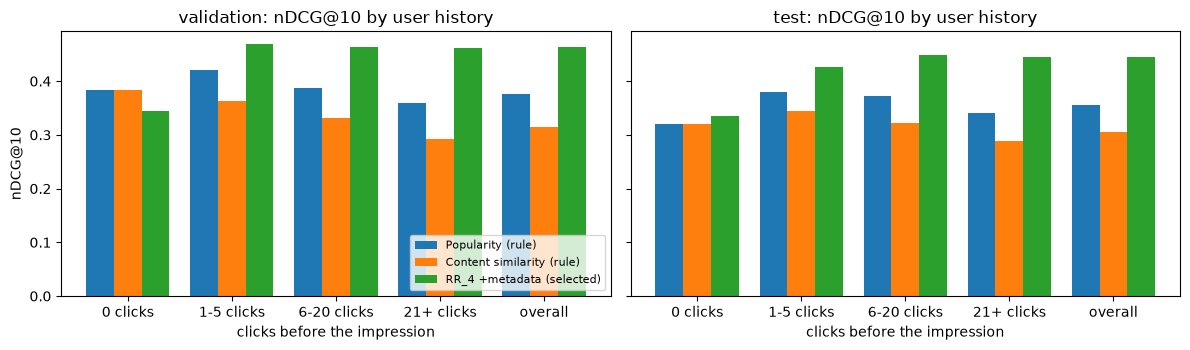

In [22]:
fig, axes = plt.subplots(1, len(SPLITS), figsize=(6 * len(SPLITS), 3.6), sharey=True)
axes = np.atleast_1d(axes)
width = 0.8 / len(MODEL_NAMES)
for axis, split in zip(axes, SPLITS):
    frame = by_history.filter(pl.col("split") == split)
    overall_split = overall.filter(pl.col("split") == split)
    groups = cohort_order + ["overall"]
    for index, model_name in enumerate(MODEL_NAMES):
        values = [
            frame.filter((pl.col("model") == model_name) & (pl.col("cohort") == cohort))["ndcg_at_10"][0]
            for cohort in cohort_order
        ] + [overall_split.filter(pl.col("model") == model_name)["ndcg_at_10"][0]]
        axis.bar(np.arange(len(groups)) + (index - (len(MODEL_NAMES) - 1) / 2) * width,
                 values, width, label=MODEL_LABELS[model_name])
    axis.set_xticks(np.arange(len(groups)), groups)
    axis.set(title=f"{split}: nDCG@10 by user history", xlabel="clicks before the impression")
axes[0].set_ylabel("nDCG@10")
axes[0].legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

# 6. Example Slate

One validation impression, ranked by each model side by side. The click label is shown only to
read the example; no model sees it.

In [23]:
EXAMPLE_TOP_N = 10
_, example_labels = scan_split("validation")
example_uid = (
    slate_sizes["validation"]
    .filter(pl.col("slate_size").is_between(15, 40) & (pl.col("clicks") == 1))
    .join(cohorts_by_split["validation"].filter(pl.col("history_length") >= 6), on="impression_uid")
    .sort("impression_uid")["impression_uid"][0]
)
slate = example_labels.filter(pl.col("impression_uid") == example_uid).select("news_code", "clicked").collect()
for model_name in MODEL_NAMES:
    ranks = (
        pl.scan_parquet(score_path(model_name, "validation"))
        .filter(pl.col("impression_uid") == example_uid)
        .collect()
        .sort(["score", "news_code"], descending=[True, False])
        .with_row_index("rank", offset=1)
        .select("news_code", pl.col("rank").alias(MODEL_LABELS[model_name]))
    )
    slate = slate.join(ranks, on="news_code")

print(f"Impression {example_uid}: {slate.height} shown articles, "
      f"user history {cohorts_by_split['validation'].filter(pl.col('impression_uid') == example_uid)['history_length'][0]} clicks")
display(slate.sort(MODEL_LABELS[FINAL_MODEL_NAME]).head(EXAMPLE_TOP_N))
print("Rank of the clicked article under each model:")
display(slate.filter(pl.col("clicked") == 1))

Impression 10000012: 16 shown articles, user history 56 clicks


news_code,clicked,Popularity (rule),Content similarity (rule),RR_4 +metadata (selected)
i64,i8,u32,u32,u32
39010,0,2,8,1
51048,0,4,1,2
287,0,1,13,3
34876,0,5,7,4
53470,0,6,4,5
4913,0,9,5,6
64094,0,14,6,7
59673,0,3,11,8
21420,1,11,15,9


Rank of the clicked article under each model:


news_code,clicked,Popularity (rule),Content similarity (rule),RR_4 +metadata (selected)
i64,i8,u32,u32,u32
21420,1,11,15,9


# 7. Save Outputs

- `RESULTS/pe_rr_only_overall.csv`: one row per model and split
- `RESULTS/pe_rr_only_by_history.csv`: one row per model, split and history cohort
- `RESULTS/pe_rr_only_metadata.json`: inputs, checkpoint settings and headline metrics

In [24]:
overall_path = RESULTS / "pe_rr_only_overall.csv"
by_history_path = RESULTS / "pe_rr_only_by_history.csv"
metadata_path = RESULTS / "pe_rr_only_metadata.json"

overall.write_csv(overall_path)
by_history.write_csv(by_history_path)
metadata_path.write_text(json.dumps({
    "created_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "environment": ENVIRONMENT,
    "splits": list(SPLITS),
    "models": {name: MODEL_LABELS[name] for name in MODEL_NAMES},
    "content_rule": CONTENT_RULE,
    "selected_model": {
        "name": FINAL_MODEL_NAME,
        "checkpoint": str(MODEL_DIR / FINAL_MODEL_NAME / "model.pt"),
        "config": checkpoint["config"],
        "loss": checkpoint["loss"],
        "best_epoch": checkpoint["best_epoch"],
    },
    "reproduces_rr4": bool(checks["matches"].all()),
    "scores_reused": REUSE_SCORES,
    "history_cohorts": cohort_order,
    "headline": {
        f"{row['model']}@{row['split']}": {m: row[m] for m in ("mrr", "ndcg_at_5", "ndcg_at_10", "recall_at_10")}
        for row in overall.iter_rows(named=True)
    },
}, indent=2, default=str))

for path in (overall_path, by_history_path, metadata_path):
    print("Saved:", path)

Saved: /Users/numkoos/Downloads/v3-mindsmall/results/pe_rr_only_overall.csv
Saved: /Users/numkoos/Downloads/v3-mindsmall/results/pe_rr_only_by_history.csv
Saved: /Users/numkoos/Downloads/v3-mindsmall/results/pe_rr_only_metadata.json


# 8. Notes and Limitations

- **Logged slates only.** Each model reorders the articles MIND actually showed, so every
  candidate has a label. This isolates ranking quality but is easier than the deployed task,
  where the reranker also faces generated candidates that were never shown (see `2_CG_RR_E2E`).
- **Selection was done upstream.** The content rule and the RR_4 architecture and loss were
  chosen on validation in `5_02_Reranking`. Test is reported here and never used for a choice.
- **Popularity is a strong baseline on logged slates.** The logging policy already favoured
  popular articles, so the shown slates are biased towards what popularity ranks well.
- **Observed CTR lift** is relative to the popularity baseline on the same logged slates. It
  is an offline proxy, not an estimate of online CTR.
- **Cohorts** use the user's click history strictly before each impression, the same causal
  history the models see.